# Atividade T1 — Problema *Splitwise*: algoritmos construtivos e busca local

**PPGI/CT/UFES — Meta-heurísticas — 2026/2**

**Aluno:** Gabriel Falcone

Este notebook implementa e analisa, para o problema de otimização combinatória *Splitwise* (minimizar o número de transações necessárias para quitar um grupo de pessoas com dívidas cruzadas):

1. dois **algoritmos construtivos** — guloso (ACG) e randomizado (ACR);
2. dois **algoritmos de busca local** que usam a mesma vizinhança, com estratégias *first-improvement* (BL_FI) e *best-improvement* (BL_BI);
3. a **tabela consolidada** de resultados (padrão da Tabela 1 da especificação), o **gráfico** construtivo × busca local, a **análise** dos resultados e as **conclusões**.

Todos os experimentos usam as 32 instâncias da pasta compartilhada da disciplina (`instancia_splitwise_*.txt`). O notebook é reproduzível: os construtivos e as buscas locais são determinísticos (o ACR usa semente fixa); apenas os tempos dependem da máquina.

**Sumário**
1. O problema
2. Instâncias
3. Representação da solução e função objetivo
4. Algoritmos construtivos (ACG e ACR)
5. Busca local (BL_FI e BL_BI)
6. Apresentação dos resultados (tabela, gráfico, análise, linha para a planilha)
7. Principais conclusões

## 1. O problema *Splitwise*

Dado um conjunto de pessoas $P=\{1,\dots,n\}$ e um vetor de saldos líquidos $B=(b_1,\dots,b_n)$ com $\sum_i b_i=0$ ($b_i>0$: a pessoa $i$ deve **receber** $b_i$; $b_i<0$: deve **pagar** $-b_i$; $b_i=0$: já está quitada), uma solução é um conjunto de transações $(i,j,v)$ — a pessoa $i$ paga $v$ à pessoa $j$ — que deixa todas as pessoas com saldo zero. O objetivo é **minimizar o número de transações**.

**Exemplo da especificação.** Saldos $(+70,+50,-40,-80)$. A solução $4\to1{:}70$, $3\to2{:}40$, $4\to2{:}10$ usa 3 transações e quita todos.

### 1.1 Estrutura do problema: partição em grupos de soma zero

Seja $P'$ o conjunto das pessoas com saldo diferente de zero e $n'=|P'|$. Duas observações caracterizam o problema:

1. **Toda solução induz uma partição de $P'$ em grupos de soma zero.** As transações formam um grafo sobre as pessoas; cada componente conexa desse grafo tem soma de saldos nula (o dinheiro só circula dentro da componente) e, por ser conexa, uma componente com $m$ pessoas contém **pelo menos $m-1$** transações.
2. **$m-1$ transações bastam para quitar qualquer grupo de $m$ pessoas com soma zero:** basta encadeá-las — a pessoa 1 repassa seu saldo à pessoa 2, que repassa o acumulado à pessoa 3, e assim por diante; a última fica com resíduo zero.

Logo, se $P'$ é particionado em $k$ grupos de soma zero, existe uma solução com $n'-k$ transações, e o valor ótimo é

$$f^{*}=n'-k_{\max},$$

onde $k_{\max}$ é o **maior número de grupos de soma zero** em que $P'$ pode ser particionado. Decidir se existe um subconjunto de soma zero é o problema *Subset-Sum* (NP-completo); a redução apresentada no blog citado na especificação (Anton Cao) mostra que o *Splitwise* é NP-difícil, o que justifica o uso de heurísticas construtivas e de busca local.

**Limite inferior.** Todo grupo de soma zero precisa de pelo menos um credor e um devedor; portanto $k_{\max}\le\min(\#\text{credores},\#\text{devedores})$ e

$$LB=n'-\min(\#\text{credores},\#\text{devedores})\le f^{*}.$$

O limite só é atingido se todos os grupos forem pares $\{+x,-x\}$ — é fraco, mas serve de referência na análise. Pessoas com saldo zero não participam de transação alguma em uma solução ótima e são ignoradas pelos algoritmos.

## 2. Instâncias

Cada arquivo `instancia_splitwise_<n>[_<k>].txt` tem uma linha `id saldo` por pessoa. Nas instâncias `n_k`, o gerador plantou pelo menos $k$ subconjuntos de soma zero (regras da pasta compartilhada), logo existe solução com $n'-k$ transações — usamos esse valor como referência na análise.

**Como carregar os dados.** O notebook procura a pasta `instancias/` no diretório de trabalho. No Google Colab, execute a célula abaixo e envie o arquivo `instancias.zip` quando solicitado — os arquivos `instancia_splitwise_*.txt` são extraídos para `instancias/` independentemente de estarem na raiz do zip ou em subpastas (ou monte o Google Drive e ajuste `PASTA_INSTANCIAS`).

In [1]:
import os, glob, re, time, math, random, bisect, zipfile, platform, sys
from collections import defaultdict
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PASTA_INSTANCIAS = 'instancias'      # pasta com os arquivos instancia_splitwise_*.txt
PASTA_RESULTADOS = 'resultados'      # tabela (CSV), gráfico (PNG) e linha da planilha são salvos aqui
os.makedirs(PASTA_RESULTADOS, exist_ok=True)

def extrair_instancias(arquivo_zip, destino):
    '''Extrai apenas os arquivos instancia_splitwise_*.txt do zip (em qualquer subpasta) para `destino`.'''
    os.makedirs(destino, exist_ok=True)
    with zipfile.ZipFile(arquivo_zip) as z:
        for membro in z.infolist():
            base = os.path.basename(membro.filename)
            if base.startswith('instancia_splitwise_') and base.endswith('.txt'):
                with z.open(membro) as origem, open(os.path.join(destino, base), 'wb') as saida:
                    saida.write(origem.read())

if not os.path.isdir(PASTA_INSTANCIAS):
    if os.path.isfile('instancias.zip'):                    # zip já presente no diretório de trabalho
        extrair_instancias('instancias.zip', PASTA_INSTANCIAS)
    else:
        try:                                               # Google Colab: envio do instancias.zip
            from google.colab import files
            print('Pasta de instâncias não encontrada. Envie o arquivo instancias.zip:')
            for nome_arq in files.upload():
                if nome_arq.endswith('.zip'):
                    extrair_instancias(nome_arq, PASTA_INSTANCIAS)
        except ImportError:
            raise FileNotFoundError(f"Pasta '{PASTA_INSTANCIAS}' não encontrada: ajuste PASTA_INSTANCIAS.")

print('Python', sys.version.split()[0], '|', platform.platform(), '|', platform.processor() or platform.machine())

Python 3.12.3 | macOS-26.6.2-arm64-arm-64bit | arm


In [2]:
def ler_instancia(caminho):
    '''Lê um arquivo com uma linha "id saldo" por pessoa e devolve {id: saldo}.'''
    saldos = {}
    with open(caminho, encoding='utf-8') as arq:
        for linha in arq:
            partes = linha.split()
            if len(partes) >= 2:
                saldos[int(partes[0])] = int(partes[1])
    if sum(saldos.values()) != 0:
        raise ValueError(f'Instância inviável ({caminho}): soma dos saldos = {sum(saldos.values())}')
    return saldos


def nome_curto(caminho):
    '''"instancia_splitwise_500_188.txt" -> "500_188".'''
    return os.path.basename(caminho).replace('instancia_splitwise_', '').replace('.txt', '')


def chave_ordenacao(caminho):
    '''Ordena por n (primeiro número do nome) e depois pelo nome.'''
    return (int(re.findall(r'\d+', os.path.basename(caminho))[0]), os.path.basename(caminho))


def limite_inferior(saldos):
    '''LB = n' - min(#credores, #devedores): todo grupo precisa de >= 1 credor e >= 1 devedor.'''
    ncred = sum(1 for v in saldos.values() if v > 0)
    ndev = sum(1 for v in saldos.values() if v < 0)
    return (ncred + ndev) - min(ncred, ndev)


def k_plantado(nome):
    '''Número de grupos plantados nas instâncias "n_k" (None nas demais).'''
    partes = nome.split('_')
    return int(partes[1]) if len(partes) > 1 else None


arquivos = sorted(glob.glob(os.path.join(PASTA_INSTANCIAS, '**', 'instancia_splitwise_*.txt'), recursive=True), key=chave_ordenacao)
instancias = [(nome_curto(a), ler_instancia(a)) for a in arquivos]
print(f'{len(instancias)} instâncias lidas: {[nome for nome, _ in instancias]}')

resumo = []
for nome, saldos in instancias:
    vals = list(saldos.values())
    nz = [v for v in vals if v != 0]
    ncred, ndev = sum(1 for v in nz if v > 0), sum(1 for v in nz if v < 0)
    k = k_plantado(nome)
    resumo.append({'I': nome, 'n': len(vals), "n'": len(nz), '#credores': ncred, '#devedores': ndev,
                   'saldo mín': min(vals), 'saldo máx': max(vals), 'LB': limite_inferior(saldos),
                   'k plantado': k if k else '-', "ref. n'-k": len(nz) - k if k else '-'})
tabela_instancias = pd.DataFrame(resumo)
tabela_instancias.style.hide(axis='index')

32 instâncias lidas: ['20', '30', '30_5', '50', '50_8', '100', '100_20', '150', '150_15', '200', '200_8', '200_80', '300', '300_60', '400', '400_35', '500', '500_188', '500_25', '600', '600_40', '700', '700_90', '800', '800_80', '900', '900_100', '1000', '1000_120', '1100', '1300', '1500']


I,n,n',#credores,#devedores,saldo mín,saldo máx,LB,k plantado,ref. n'-k
20,20,20,10,10,-100001,100001,10,-,-
30,30,30,15,15,-100002,100002,15,-,-
30_5,30,30,15,15,-542,196,15,5,25
50,50,50,25,25,-100003,100003,25,-,-
50_8,50,50,26,24,-103,60,26,8,42
100,100,100,50,50,-100005,100005,50,-,-
100_20,100,100,48,52,-200,164,52,20,80
150,150,150,75,75,-100008,100008,75,-,-
150_15,150,150,77,73,-445451,350315,77,15,135
200,200,200,100,100,-100010,100010,100,-,-


## 3. Representação da solução e função objetivo

Pela Seção 1.1, resolver o problema é encontrar uma partição de $P'$ com o **maior número possível de grupos de soma zero**. Em vez de manipular a partição diretamente — o que exigiria movimentos que preservem a soma zero de cada grupo, um subproblema de *subset-sum* —, representamos a solução por uma **permutação** $\pi=(\pi_1,\dots,\pi_{n'})$ das pessoas de $P'$, decodificada como uma **cadeia de repasses**:

* $S_t=b_{\pi_1}+\dots+b_{\pi_t}$ é a soma-prefixo (resíduo acumulado) após as $t$ primeiras pessoas;
* se $S_t>0$, a pessoa $\pi_{t+1}$ paga $S_t$ a $\pi_t$; se $S_t<0$, $\pi_t$ paga $-S_t$ a $\pi_{t+1}$; se $S_t=0$, **nenhuma transação** é feita — o grupo iniciado após o último zero está quitado e um novo grupo começa em $\pi_{t+1}$.

A função objetivo é o número de transações da cadeia:

$$f(\pi)=\bigl|\{\,t\in\{1,\dots,n'-1\}:S_t\neq0\,\}\bigr|=n'-k(\pi),$$

onde $k(\pi)$ é o número de grupos da solução (segmentos entre zeros consecutivos de $S$, contando $S_{n'}=0$). Propriedades da representação:

* **toda permutação é uma solução viável** — a cadeia sempre quita todos, pois $S_{n'}=\sum_i b_i=0$; não há restrições a tratar na busca local;
* **toda partição em grupos de soma zero é representável** (basta concatenar os grupos): o espaço de busca contém a solução ótima;
* o construtivo produz a permutação diretamente (a ordem em que insere as pessoas) e a busca local opera sobre ela com vizinhanças clássicas de permutação (slides de busca local), com **avaliação incremental** do $\Delta f$.

No exemplo da especificação, $\pi=(1,4,2,3)$ dá $S=(70,-10,40,0)$ e exatamente as três transações apresentadas: $4\to1{:}70$, $4\to2{:}10$, $3\to2{:}40$.

In [3]:
def somas_prefixo(valores):
    '''S[t] = valores[0] + ... + valores[t].'''
    S, acc = [], 0
    for v in valores:
        acc += v
        S.append(acc)
    return S


def funcao_objetivo(valores):
    '''f = nº de transações da cadeia = nº de somas-prefixo internas (t = 0..n'-2) diferentes de zero.'''
    S = somas_prefixo(valores)
    return sum(1 for t in range(len(S) - 1) if S[t] != 0)


def decodificar(perm, saldos):
    '''Transforma a permutação (cadeia de repasses) em transações (pagador, recebedor, valor)
    e na partição em grupos de soma zero.'''
    valores = [saldos[i] for i in perm]
    S = somas_prefixo(valores)
    transacoes, grupos, grupo = [], [], []
    for t in range(len(perm)):
        grupo.append(perm[t])
        if S[t] == 0:                      # resíduo zerou: fecha o grupo, nenhum repasse
            grupos.append(grupo)
            grupo = []
        elif S[t] > 0:                     # resíduo a receber: o próximo paga ao atual
            transacoes.append((perm[t + 1], perm[t], S[t]))
        else:                              # resíduo a pagar: o atual paga ao próximo
            transacoes.append((perm[t], perm[t + 1], -S[t]))
    return transacoes, grupos


def verificar(saldos, transacoes):
    '''Aplica as transações aos saldos e confere que todos ficam quitados (viabilidade).'''
    b = dict(saldos)
    for pagador, recebedor, valor in transacoes:
        if valor <= 0:
            return False
        b[pagador] += valor       # quem paga reduz a dívida (saldo negativo sobe)
        b[recebedor] -= valor     # quem recebe reduz o crédito (saldo positivo desce)
    return all(v == 0 for v in b.values())


# Exemplo da especificação
exemplo = {1: 70, 2: 50, 3: -40, 4: -80}
pi = [1, 4, 2, 3]
transacoes, grupos = decodificar(pi, exemplo)
print('permutação:', pi, '| somas-prefixo:', somas_prefixo([exemplo[i] for i in pi]))
print('transações (pagador -> recebedor: valor):', ', '.join(f'{p}->{r}:{v}' for p, r, v in transacoes))
print('f =', funcao_objetivo([exemplo[i] for i in pi]), '| grupos:', grupos, '| viável:', verificar(exemplo, transacoes))

permutação: [1, 4, 2, 3] | somas-prefixo: [70, -10, 40, 0]
transações (pagador -> recebedor: valor): 4->1:70, 4->2:10, 3->2:40
f = 3 | grupos: [[1, 4, 2, 3]] | viável: True


## 4. Algoritmos construtivos

Os dois construtivos montam a cadeia (permutação) **elemento a elemento**, mantendo o resíduo acumulado $r=S_t$ do grupo em construção. A cada passo há dois tipos de decisão:

* **Abertura de grupo** ($r=0$): os candidatos são ordenados por $|b_j|$ decrescente — começar pelos maiores saldos (os mais difíceis de compensar), como na regra LPT/*first-fit decreasing*.
* **Extensão do grupo** ($r\neq0$): os candidatos são as pessoas com saldo de sinal **oposto** a $r$, ordenadas pela **função gulosa** $g(j)=|r+b_j|$ — o resíduo que restaria após incluir $j$ (empate: maior $|b_j|$). Um candidato com $g(j)=0$ fecha o grupo imediatamente (uma transação a menos); caso contrário, a escolha deixa o resíduo o mais próximo possível de zero, aumentando a chance de fechar o grupo nos passos seguintes.

Como $\sum_i b_i=0$, enquanto $r\neq0$ sempre existe candidato de sinal oposto; o procedimento termina com todos os grupos fechados e a solução é sempre viável.

**ACG (guloso).** Escolhe sempre o primeiro candidato da lista ordenada (escolha local ótima). A regra clássica do aplicativo Splitwise — "o maior devedor paga ao maior credor" — corresponde a escolher, na extensão, o candidato de maior $|b_j|$ em vez do de menor $|r+b_j|$ — uma escolha que zera o resíduo com menos frequência.

**ACR (randomizado).** Monta uma **lista restrita de candidatos (LRC)** com os $k_{LRC}$ melhores candidatos segundo o mesmo critério e escolhe um deles **uniformemente ao acaso** (como na fase de construção do GRASP). Usamos $k_{LRC}=3$ e semente fixa (42) para reprodutibilidade; $k_{LRC}=1$ recupera o ACG.

Pseudocódigo comum:

```text
construtivo(B, k_LRC):
    C ← pessoas com saldo ≠ 0;  π ← ();  r ← 0
    enquanto C ≠ ∅:
        se r = 0:  L ← as k_LRC pessoas de C com maior |b_j|
        senão:     L ← as k_LRC pessoas de C com sinal oposto a r e menor |r + b_j|
        j ← primeira de L (ACG)   ou   escolha uniforme em L (ACR)
        π ← π + (j);  r ← r + b_j;  C ← C \ {j}
    devolver π
```

Implementação: credores e devedores ficam em listas ordenadas por $|b|$; os candidatos mais próximos de $|r|$ são localizados por busca binária (`bisect`). Cada passo custa $O(\log n'+n')$ (a remoção da lista é $O(n')$), logo o construtivo é $O(n'^2)$ no pior caso — na prática, cerca de 1 ms para $n'=1500$.

In [4]:
def _construir(saldos, k_lrc=1, rng=None):
    '''Núcleo comum dos construtivos. Constrói a permutação (cadeia) elemento a elemento:
      * resíduo r == 0 (abertura de grupo): candidatos = pessoas de maior |saldo|;
      * resíduo r != 0 (extensão do grupo): candidatos = pessoas de sinal oposto a r,
        ordenadas pela função gulosa g(j) = |r + b_j| (empate: maior |b_j|).
    A LRC contém os k_lrc melhores candidatos; a escolha é o 1º (guloso, rng=None)
    ou uniforme na LRC (randomizado).'''
    cred = sorted((v, i) for i, v in saldos.items() if v > 0)    # credores: (valor, id) crescente
    dev = sorted((-v, i) for i, v in saldos.items() if v < 0)    # devedores: (|valor|, id) crescente
    perm, r = [], 0
    while cred or dev:
        if r == 0:
            cand = [(-cred[idx][0], +1, idx) for idx in range(max(0, len(cred) - k_lrc), len(cred))]
            cand += [(-dev[idx][0], -1, idx) for idx in range(max(0, len(dev) - k_lrc), len(dev))]
            cand.sort()                                          # maior |saldo| primeiro
            lrc = [(sinal, idx) for _, sinal, idx in cand[:k_lrc]]
        else:
            lista, sinal = (dev, -1) if r > 0 else (cred, +1)   # sinal oposto ao resíduo
            alvo = abs(r)
            p = bisect.bisect_left(lista, (alvo, -1))            # vizinhos de |r| na lista ordenada
            cand = [(abs(lista[idx][0] - alvo), -lista[idx][0], idx)
                    for idx in range(max(0, p - k_lrc), min(len(lista), p + k_lrc))]
            cand.sort()                                          # menor |r + b_j| primeiro
            lrc = [(sinal, idx) for _, _, idx in cand[:k_lrc]]
        sinal, idx = lrc[0] if rng is None else rng.choice(lrc)
        lista = cred if sinal > 0 else dev
        m, i = lista.pop(idx)
        perm.append(i)
        r += sinal * m
    return perm


def construtivo_guloso(saldos):
    '''ACG: escolha local ótima (1º da lista de candidatos).'''
    return _construir(saldos, k_lrc=1, rng=None)


def construtivo_randomizado(saldos, k_lrc=3, semente=None):
    '''ACR: escolha uniforme entre os k_lrc melhores candidatos (LRC).'''
    return _construir(saldos, k_lrc=k_lrc, rng=random.Random(semente))


# Exemplo da especificação
pi_g = construtivo_guloso(exemplo)
print('ACG no exemplo: π =', pi_g, '| f =', funcao_objetivo([exemplo[i] for i in pi_g]),
      '| transações:', decodificar(pi_g, exemplo)[0])

ACG no exemplo: π = [4, 1, 2, 3] | f = 3 | transações: [(4, 1, 80), (1, 2, 10), (3, 2, 40)]


### 4.1 Execução dos construtivos em todas as instâncias

In [5]:
K_LRC, SEMENTE = 3, 42
sol_construtivo = {}            # (algoritmo, instância) -> permutação
res_construtivo = []
for nome, saldos in instancias:
    linha = {'I': nome}
    t0 = time.perf_counter(); p_acg = construtivo_guloso(saldos); t_acg = time.perf_counter() - t0
    t0 = time.perf_counter(); p_acr = construtivo_randomizado(saldos, K_LRC, SEMENTE); t_acr = time.perf_counter() - t0
    for alg, p, t in (('ACG', p_acg, t_acg), ('ACR', p_acr, t_acr)):
        transacoes, grupos = decodificar(p, saldos)
        assert verificar(saldos, transacoes) and len(transacoes) == funcao_objetivo([saldos[i] for i in p])
        sol_construtivo[(alg, nome)] = p
        linha[f'{alg} sol'] = len(transacoes)
        linha[f'{alg} t(s)'] = t
        linha[f'{alg} grupos'] = len(grupos)
        linha[f'{alg} maior grupo'] = max(len(g) for g in grupos)
    linha['LB'] = limite_inferior(saldos)
    res_construtivo.append(linha)
tabela_construtivos = pd.DataFrame(res_construtivo)
tabela_construtivos.style.hide(axis='index').format({'ACG t(s)': '{:.4f}', 'ACR t(s)': '{:.4f}'})

I,ACG sol,ACG t(s),ACG grupos,ACG maior grupo,ACR sol,ACR t(s),ACR grupos,ACR maior grupo,LB
20,16,0.0000,4,11,19,0.0000,1,20,10
30,27,0.0000,3,26,26,0.0000,4,16,15
30_5,27,0.0000,3,11,28,0.0000,2,22,15
50,40,0.0000,10,15,47,0.0000,3,40,25
50_8,46,0.0000,4,26,46,0.0000,4,36,26
100,84,0.0001,16,31,93,0.0001,7,55,50
100_20,95,0.0000,5,41,97,0.0001,3,74,52
150,128,0.0001,22,50,139,0.0001,11,77,75
150_15,149,0.0001,1,150,149,0.0001,1,150,77
200,166,0.0001,34,42,183,0.0002,17,41,100


## 5. Busca local

### 5.1 Vizinhança de troca (*swap*)

Usamos a vizinhança $N_2$ dos slides — **troca de duas posições** da permutação:

$$N(\pi)=\{\pi^{(i,j)}:1\le i<j\le n'\},\qquad |N(\pi)|=\frac{n'(n'-1)}{2}.$$

Trocar $\pi_i$ e $\pi_j$ altera **apenas** as somas-prefixo $S_t$ com $i\le t<j$, todas deslocadas pelo mesmo valor $\delta=b_{\pi_j}-b_{\pi_i}$. O vizinho é, portanto, avaliado **incrementalmente** (atualização por valor delta, como nos slides):

$$\Delta f=\underbrace{|\{t\in[i,j):S_t=0\}|}_{\text{zeros perdidos}}-\underbrace{|\{t\in[i,j):S_t=-\delta\}|}_{\text{zeros ganhos}}.$$

Os zeros perdidos são acumulados à medida que $j$ cresce; os ganhos são contados com um dicionário *valor → posições ordenadas* das somas-prefixo e duas buscas binárias. Cada vizinho custa $O(\log n')$ — na prática $O(1)$, pois o valor $-\delta$ quase nunca ocorre — contra $O(n')$ de uma reavaliação completa; uma varredura da vizinhança custa $O(n'^2\log n')$, cerca de 1,1 milhão de vizinhos para $n'=1500$.

Intuição do movimento: uma troca **dentro** de um grupo faz um prefixo do grupo (com uma pessoa substituída) somar zero, **dividindo o grupo em dois** ($\Delta f=-1$); trocas **entre** grupos destroem o(s) zero(s) entre eles e só melhoram se criarem mais zeros do que destroem. A vizinhança é rica em platôs: a grande maioria das trocas tem $\Delta f=0$.

### 5.2 Estratégias *first-improvement* (FI) e *best-improvement* (BI)

As duas buscas seguem os pseudocódigos dos slides sobre a **mesma vizinhança**, enumerada na mesma ordem lexicográfica $(i,j)$:

* **BL_FI**: aceita o **primeiro** vizinho com $\Delta f<0$ e recomeça a varredura;
* **BL_BI** (descida mais rápida): avalia **toda** a vizinhança e aceita o melhor vizinho, se $\Delta f_{\min}<0$.

Ambas param em um **ótimo local** (nenhum vizinho melhor). $N_{It}$ é o número de execuções do laço `while` mais externo — inclui a última iteração, que apenas certifica o ótimo local. Como $f$ é inteiro e decresce a cada iteração, $N_{It}\le f(\pi_0)+1$.

In [6]:
def _indice_prefixos(S):
    '''valor -> lista crescente das posições internas t (0..n'-2) com S[t] == valor.'''
    D = defaultdict(list)
    for t in range(len(S) - 1):
        D[S[t]].append(t)
    return D


def vizinhanca_troca(valores, S, D):
    '''Enumera todos os vizinhos por troca (i < j, ordem lexicográfica) e devolve
    (delta_f, i, j), onde delta_f = f(s') - f(s) é obtido por avaliação incremental:
    a troca desloca S[t] em delta = b_j - b_i apenas para t em [i, j-1]; logo
      zeros perdidos = nº de t em [i, j-1] com S[t] == 0
      zeros ganhos   = nº de t em [i, j-1] com S[t] == b_i - b_j.'''
    n = len(valores)
    for i in range(n - 1):
        bi, perdidos = valores[i], 0
        for j in range(i + 1, n):
            if S[j - 1] == 0:
                perdidos += 1                         # a posição j-1 entrou no intervalo [i, j-1]
            bj = valores[j]
            if bj == bi:
                continue                              # trocar saldos iguais não altera a solução
            pos = D.get(bi - bj)
            ganhos = (bisect.bisect_left(pos, j) - bisect.bisect_left(pos, i)) if pos else 0
            yield perdidos - ganhos, i, j


def _aplicar_troca(perm, valores, i, j):
    perm[i], perm[j] = perm[j], perm[i]
    valores[i], valores[j] = valores[j], valores[i]


def busca_local_FI(perm, saldos):
    '''Busca local first-improvement (pseudocódigo dos slides): aceita o 1º vizinho melhor.
    Devolve (perm, f, NIt, nº de vizinhos avaliados).'''
    perm = list(perm)
    valores = [saldos[i] for i in perm]
    S = somas_prefixo(valores)
    D = _indice_prefixos(S)
    f = funcao_objetivo(valores)
    n_it, n_aval, melhoria = 0, 0, True
    while melhoria:
        n_it += 1
        melhoria = False
        for delta, i, j in vizinhanca_troca(valores, S, D):      # for-all s' em N(s) e melhoria = falso
            n_aval += 1
            if delta < 0:                                        # f(s') < f(s)
                _aplicar_troca(perm, valores, i, j)              # s <- s'
                f += delta
                S = somas_prefixo(valores)
                D = _indice_prefixos(S)
                melhoria = True
                break
    return perm, f, n_it, n_aval


def busca_local_BI(perm, saldos):
    '''Busca local best-improvement / descida mais rápida (pseudocódigo dos slides):
    avalia toda a vizinhança e aceita o melhor vizinho, se ele melhorar a solução.'''
    perm = list(perm)
    valores = [saldos[i] for i in perm]
    S = somas_prefixo(valores)
    D = _indice_prefixos(S)
    f = funcao_objetivo(valores)
    n_it, n_aval, melhoria = 0, 0, True
    while melhoria:
        n_it += 1
        melhoria = False
        delta_min, melhor = math.inf, None                       # f_min <- +inf
        for delta, i, j in vizinhanca_troca(valores, S, D):      # for-all s' em N(s)
            n_aval += 1
            if delta < delta_min:                                # f(s') < f_min
                delta_min, melhor = delta, (i, j)                # s_min <- s'
        if delta_min < 0:                                        # f_min < f(s)
            _aplicar_troca(perm, valores, *melhor)               # s <- s_min
            f += delta_min
            S = somas_prefixo(valores)
            D = _indice_prefixos(S)
            melhoria = True
    return perm, f, n_it, n_aval


# Exemplo pequeno: instância "20" partindo do ACG
saldos20 = dict(instancias)['20']
p0 = sol_construtivo[('ACG', '20')]
for nome_bl, bl in (('BL_FI', busca_local_FI), ('BL_BI', busca_local_BI)):
    p, f, n_it, n_aval = bl(p0, saldos20)
    print(f"{nome_bl}(ACG) na instância 20: f {funcao_objetivo([saldos20[i] for i in p0])} -> {f} | NIt = {n_it} | vizinhos avaliados = {n_aval} | grupos = {decodificar(p, saldos20)[1]}")

BL_FI(ACG) na instância 20: f 16 -> 15 | NIt = 2 | vizinhos avaliados = 334 | grupos = [[18, 17], [8, 14, 4, 11], [1, 16, 7], [19, 9, 2, 20], [5, 6, 12, 3, 13, 10, 15]]
BL_BI(ACG) na instância 20: f 16 -> 15 | NIt = 2 | vizinhos avaliados = 372 | grupos = [[18, 17], [8, 14, 4, 11], [1, 16, 7], [19, 9, 2, 20], [5, 6, 12, 3, 13, 10, 15]]


### 5.3 Execução das quatro combinações (BL_FI/BL_BI × ACG/ACR) em todas as instâncias

Cada solução final é decodificada em transações e **verificada** (todas as pessoas quitadas e número de transações igual a $f$). O tempo reportado é o da busca local (o tempo do construtivo está nas colunas ACG/ACR).

In [7]:
ALGS_AC = ['ACG', 'ACR']
ALGS_BL = ['BL_FI(ACG)', 'BL_FI(ACR)', 'BL_BI(ACG)', 'BL_BI(ACR)']
sol_final = {}                  # (variante de BL, instância) -> permutação final
linhas = []
t_inicio = time.perf_counter()
for linha_c, (nome, saldos) in zip(res_construtivo, instancias):
    r = {'I': nome}
    for alg in ALGS_AC:
        r[(alg, 'sol')], r[(alg, 't(s)')] = linha_c[f'{alg} sol'], linha_c[f'{alg} t(s)']
    for nome_bl, bl in (('BL_FI', busca_local_FI), ('BL_BI', busca_local_BI)):
        for alg in ALGS_AC:
            t0 = time.perf_counter()
            perm, f, n_it, n_aval = bl(sol_construtivo[(alg, nome)], saldos)
            t = time.perf_counter() - t0
            transacoes, grupos = decodificar(perm, saldos)
            assert verificar(saldos, transacoes) and len(transacoes) == f, 'solução inválida!'
            col = f'{nome_bl}({alg})'
            r[(col, 'sol')], r[(col, 'NIt')], r[(col, 't(s)')], r[(col, 'aval')] = f, n_it, t, n_aval
            sol_final[(col, nome)] = perm
    linhas.append(r)
    print(f"{nome:>8s} | ACG {r[('ACG','sol')]:5d}  ACR {r[('ACR','sol')]:5d} | "
          + ' '.join(f"{c} {r[(c,'sol')]:5d} (NIt {r[(c,'NIt')]:3d}, {r[(c,'t(s)')]:6.3f}s)" for c in ALGS_BL))
print(f'tempo total das buscas locais: {time.perf_counter() - t_inicio:.1f} s')

      20 | ACG    16  ACR    19 | BL_FI(ACG)    15 (NIt   2,  0.000s) BL_FI(ACR)    18 (NIt   2,  0.000s) BL_BI(ACG)    15 (NIt   2,  0.000s) BL_BI(ACR)    16 (NIt   3,  0.000s)
      30 | ACG    27  ACR    26 | BL_FI(ACG)    23 (NIt   5,  0.000s) BL_FI(ACR)    23 (NIt   4,  0.000s) BL_BI(ACG)    23 (NIt   5,  0.000s) BL_BI(ACR)    23 (NIt   4,  0.000s)
    30_5 | ACG    27  ACR    28 | BL_FI(ACG)    27 (NIt   1,  0.000s) BL_FI(ACR)    27 (NIt   2,  0.000s) BL_BI(ACG)    27 (NIt   1,  0.000s) BL_BI(ACR)    27 (NIt   2,  0.000s)
      50 | ACG    40  ACR    47 | BL_FI(ACG)    38 (NIt   3,  0.000s) BL_FI(ACR)    37 (NIt  11,  0.001s) BL_BI(ACG)    38 (NIt   3,  0.000s) BL_BI(ACR)    40 (NIt   7,  0.001s)
    50_8 | ACG    46  ACR    46 | BL_FI(ACG)    41 (NIt   6,  0.000s) BL_FI(ACR)    41 (NIt   6,  0.001s) BL_BI(ACG)    38 (NIt   7,  0.001s) BL_BI(ACR)    40 (NIt   6,  0.001s)
     100 | ACG    84  ACR    93 | BL_FI(ACG)    81 (NIt   4,  0.002s) BL_FI(ACR)    82 (NIt  11,  0.003s) BL_B

     200 | ACG   166  ACR   183 | BL_FI(ACG)   157 (NIt  10,  0.018s) BL_FI(ACR)   163 (NIt  21,  0.030s) BL_BI(ACG)   158 (NIt   6,  0.012s) BL_BI(ACR)   163 (NIt  14,  0.029s)


   200_8 | ACG   169  ACR   183 | BL_FI(ACG)   148 (NIt  21,  0.037s) BL_FI(ACR)   160 (NIt  23,  0.036s) BL_BI(ACG)   150 (NIt  15,  0.032s) BL_BI(ACR)   154 (NIt  20,  0.042s)


  200_80 | ACG   196  ACR   199 | BL_FI(ACG)   168 (NIt  29,  0.034s) BL_FI(ACR)   179 (NIt  20,  0.017s) BL_BI(ACG)   175 (NIt  17,  0.030s) BL_BI(ACR)   175 (NIt  19,  0.032s)


     300 | ACG   246  ACR   260 | BL_FI(ACG)   237 (NIt  10,  0.038s) BL_FI(ACR)   249 (NIt  11,  0.049s) BL_BI(ACG)   240 (NIt   4,  0.020s) BL_BI(ACR)   249 (NIt   6,  0.029s)


...

    1000 | ACG   818  ACR   875 | BL_FI(ACG)   805 (NIt  14,  0.829s) BL_FI(ACR)   839 (NIt  36,  2.016s) BL_BI(ACG)   806 (NIt   6,  0.368s) BL_BI(ACR)   834 (NIt  25,  1.564s)


1000_120 | ACG   719  ACR   889 | BL_FI(ACG)   673 (NIt  44,  2.577s) BL_FI(ACR)   757 (NIt 121,  5.182s) BL_BI(ACG)   671 (NIt  20,  1.209s) BL_BI(ACR)   752 (NIt  69,  4.356s)


    1100 | ACG   900  ACR   907 | BL_FI(ACG)   886 (NIt  15,  0.990s) BL_FI(ACR)   882 (NIt  26,  1.798s) BL_BI(ACG)   883 (NIt  10,  0.751s) BL_BI(ACR)   883 (NIt  18,  1.367s)


    1300 | ACG  1071  ACR  1077 | BL_FI(ACG)  1043 (NIt  29,  2.732s) BL_FI(ACR)  1051 (NIt  27,  2.624s) BL_BI(ACG)  1040 (NIt  14,  1.477s) BL_BI(ACR)  1051 (NIt  21,  2.266s)


    1500 | ACG  1221  ACR  1275 | BL_FI(ACG)  1206 (NIt  16,  2.161s) BL_FI(ACR)  1247 (NIt  29,  3.709s) BL_BI(ACG)  1207 (NIt   9,  1.250s) BL_BI(ACR)  1249 (NIt  21,  2.971s)
tempo total das buscas locais: 89.9 s


## 6. Apresentação dos resultados

### 6.1 Tabela consolidada (padrão da Tabela 1)

Legenda: **I** instância; **sol** valor da função objetivo (número de transações); **t(s)** tempo de execução em segundos; **NIt** número de iterações do laço externo da busca local. Em cada linha, o **melhor valor entre as quatro buscas locais está em negrito** (empates: todos). A tabela também é salva em `resultados/tabela_resultados.csv`.

In [8]:
colunas = [('I', '')]
for a in ALGS_AC:
    colunas += [(a, 'sol'), (a, 't(s)')]
for a in ALGS_BL:
    colunas += [(a, 'sol'), (a, 'NIt'), (a, 't(s)')]
tabela = pd.DataFrame([[r['I']] + [r[c] for c in colunas[1:]] for r in linhas],
                      columns=pd.MultiIndex.from_tuples(colunas))
tabela.to_csv(os.path.join(PASTA_RESULTADOS, 'tabela_resultados.csv'), index=False)

cols_sol_bl = [(a, 'sol') for a in ALGS_BL]

def negrito_melhor_bl(linha):
    melhor = min(linha[c] for c in cols_sol_bl)
    return ['font-weight: bold' if (c in cols_sol_bl and linha[c] == melhor) else '' for c in linha.index]

(tabela.style.apply(negrito_melhor_bl, axis=1)
       .format({c: '{:.4f}' for c in tabela.columns if c[1] == 't(s)'})
       .hide(axis='index')
       .set_table_styles([{'selector': 'th', 'props': 'text-align:center; padding:2px 6px;'},
                          {'selector': 'td', 'props': 'text-align:right; padding:2px 6px;'}]))

**Resumo por variante de busca local** — desvio relativo médio ao melhor valor da linha, número de vitórias (linhas em que a variante atinge o melhor valor) e totais de iterações, vizinhos avaliados e tempo. A variante com menor desvio médio é usada no gráfico do item 6.2.

In [9]:
sol_bl = tabela[cols_sol_bl].copy(); sol_bl.columns = ALGS_BL
melhor_linha = sol_bl.min(axis=1)
resumo_bl = pd.DataFrame({
    'desvio médio ao melhor (%)': (sol_bl.sub(melhor_linha, axis=0).div(melhor_linha, axis=0) * 100).mean().round(2),
    'vitórias': sol_bl.eq(melhor_linha, axis=0).sum(),
    'sol média': sol_bl.mean().round(1),
    'NIt total': [tabela[(a, 'NIt')].sum() for a in ALGS_BL],
    'vizinhos avaliados (milhões)': [round(sum(r[(a, 'aval')] for r in linhas) / 1e6, 1) for a in ALGS_BL],
    'tempo total (s)': [round(tabela[(a, 't(s)')].sum(), 2) for a in ALGS_BL],
}).sort_values(['desvio médio ao melhor (%)', 'vitórias'], ascending=[True, False])
MELHOR_BL = resumo_bl.index[0]
CONSTRUTIVO_DA_MELHOR_BL = MELHOR_BL[MELHOR_BL.index('(') + 1:-1]
print('Melhor variante de busca local:', MELHOR_BL, '(solução inicial:', CONSTRUTIVO_DA_MELHOR_BL + ')')
resumo_bl

Melhor variante de busca local: BL_BI(ACG) (solução inicial: ACG)


,desvio médio ao melhor (%),vitórias,sol média,NIt total,vizinhos avaliados (milhões),tempo total (s)
BL_BI(ACG),0.59,15,393.3,514,133.3,15.92
BL_FI(ACG),0.74,16,393.8,749,165.3,20.42
BL_BI(ACR),2.73,6,401.5,711,204.3,25.12
BL_FI(ACR),3.23,9,402.0,1004,226.4,28.41


### 6.2 Gráfico: valor da função objetivo por instância (construtivo × melhor busca local)

Eixo x: instâncias (ordenadas por $n$); eixo y: $f$ obtido pelo construtivo associado e pela melhor variante de busca local. Os traços cinza marcam o limite inferior $LB$. O painel inferior mostra a melhoria relativa da busca local sobre o construtivo, $(f_{AC}-f_{BL})/f_{AC}$. O gráfico é salvo em `resultados/grafico_construtivo_vs_bl.png`. A tabela após o gráfico acrescenta, para cada instância, o melhor valor entre as quatro buscas locais e seus desvios em relação ao limite inferior $LB$ e à solução plantada ($n'-k$, instâncias `n_k`).

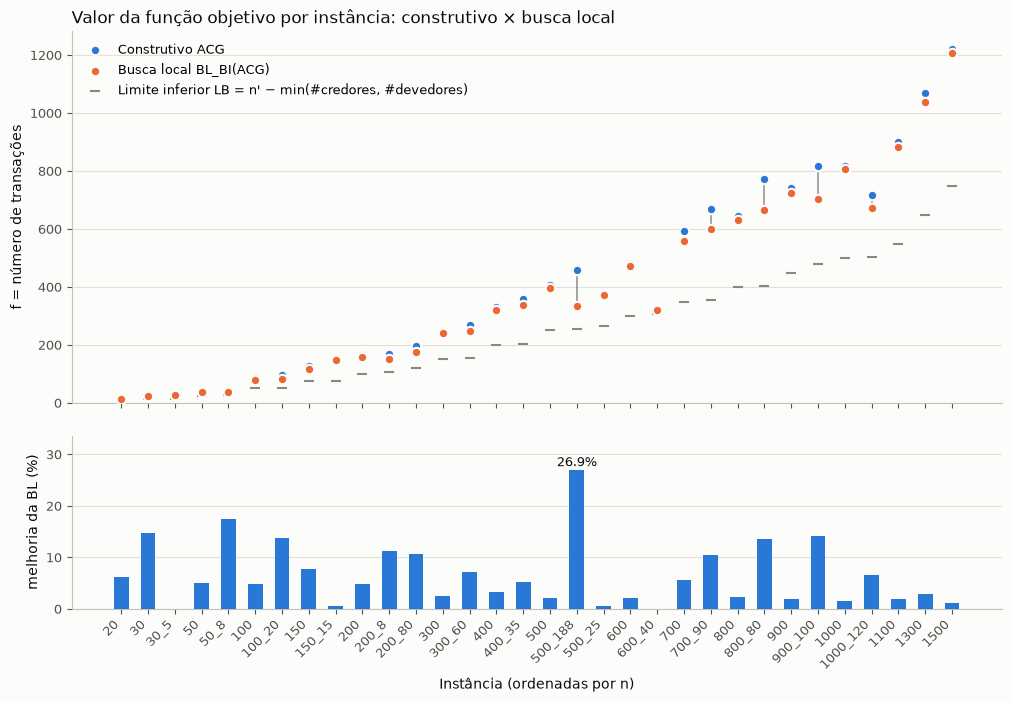

I,f ACG,f BL_BI(ACG),melhoria (%),melhor BL (4 variantes),LB,desvio ao LB (%),ref. plantada (n'-k),desvio à ref. (%)
20,16,15,6.2,15,10,50.0,-,-
30,27,23,14.8,23,15,53.3,-,-
30_5,27,27,0.0,27,15,80.0,25,8.0
50,40,38,5.0,37,25,48.0,-,-
50_8,46,38,17.4,38,26,46.2,42,-9.5
100,84,80,4.8,80,50,60.0,-,-
100_20,95,82,13.7,82,52,57.7,80,2.5
150,128,118,7.8,116,75,54.7,-,-
150_15,149,148,0.7,147,77,90.9,135,8.9
200,166,158,4.8,157,100,57.0,-,-


In [10]:
COR_1, COR_2, COR_CINZA = '#2a78d6', '#eb6834', '#898781'                    # série 1, série 2, contexto
COR_GRADE, COR_EIXO, COR_TEXTO, COR_TEXTO2, COR_FUNDO = '#e1e0d9', '#c3c2b7', '#0b0b0b', '#52514e', '#fcfcfb'

def _estilo_eixo(ax):
    ax.set_facecolor(COR_FUNDO)
    for lado in ('top', 'right'):
        ax.spines[lado].set_visible(False)
    for lado in ('left', 'bottom'):
        ax.spines[lado].set_color(COR_EIXO)
    ax.tick_params(colors=COR_TEXTO2, labelsize=9)
    ax.yaxis.grid(True, color=COR_GRADE, linewidth=0.8)
    ax.set_axisbelow(True)

nomes = tabela[('I', '')].tolist()
f_ac = tabela[(CONSTRUTIVO_DA_MELHOR_BL, 'sol')].to_numpy()
f_bl = tabela[(MELHOR_BL, 'sol')].to_numpy()
lb = np.array([limite_inferior(dict(instancias)[n]) for n in nomes])
x = np.arange(len(nomes))
melhoria = (f_ac - f_bl) / f_ac * 100

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 7.5), sharex=True,
                               gridspec_kw={'height_ratios': [3, 1.4], 'hspace': 0.12})
fig.patch.set_facecolor(COR_FUNDO)
_estilo_eixo(ax1); _estilo_eixo(ax2)
ax1.vlines(x, f_bl, f_ac, color=COR_TEXTO2, linewidth=1.2, alpha=0.6, zorder=2)
ax1.scatter(x, f_ac, s=46, color=COR_1, zorder=3, edgecolor=COR_FUNDO, linewidth=1.5,
            label=f'Construtivo {CONSTRUTIVO_DA_MELHOR_BL}')
ax1.scatter(x, f_bl, s=46, color=COR_2, zorder=4, edgecolor=COR_FUNDO, linewidth=1.5,
            label=f'Busca local {MELHOR_BL}')
ax1.scatter(x, lb, s=60, marker='_', color=COR_CINZA, zorder=2, linewidth=1.5,
            label="Limite inferior LB = n' − min(#credores, #devedores)")
ax1.set_ylabel('f = número de transações', color=COR_TEXTO)
ax1.set_title('Valor da função objetivo por instância: construtivo × busca local', loc='left', color=COR_TEXTO, fontsize=12)
ax1.legend(frameon=False, loc='upper left', fontsize=9)
ax1.set_ylim(bottom=0)
ax2.bar(x, melhoria, width=0.55, color=COR_1, zorder=3)
ax2.set_ylabel('melhoria da BL (%)', color=COR_TEXTO)
ax2.set_xticks(x); ax2.set_xticklabels(nomes, rotation=45, ha='right')
ax2.set_xlabel('Instância (ordenadas por n)', color=COR_TEXTO)
i_max = int(np.argmax(melhoria))                                                  # rótulo direto só no extremo
ax2.annotate(f'{melhoria[i_max]:.1f}%', (x[i_max], melhoria[i_max]), textcoords='offset points',
             xytext=(0, 3), ha='center', fontsize=9, color=COR_TEXTO)
ax2.set_ylim(0, melhoria.max() * 1.25)
fig.savefig(os.path.join(PASTA_RESULTADOS, 'grafico_construtivo_vs_bl.png'), dpi=150, bbox_inches='tight', facecolor=COR_FUNDO)
plt.show()

ref = [(sum(1 for v in dict(instancias)[n].values() if v != 0) - k_plantado(n)) if k_plantado(n) else None for n in nomes]
melhor_bl_linha = melhor_linha.to_numpy()
pd.DataFrame({'I': nomes, f'f {CONSTRUTIVO_DA_MELHOR_BL}': f_ac, f'f {MELHOR_BL}': f_bl, 'melhoria (%)': melhoria.round(1),
              'melhor BL (4 variantes)': melhor_bl_linha, 'LB': lb, 'desvio ao LB (%)': ((melhor_bl_linha - lb) / lb * 100).round(1),
              "ref. plantada (n'-k)": [r if r else '-' for r in ref],
              'desvio à ref. (%)': [round((b - r) / r * 100, 1) if r else '-' for b, r in zip(melhor_bl_linha, ref)]}
             ).style.hide(axis='index').format(precision=1)

### 6.3 Análise dos resultados

**Construtivos.** O ACG é muito rápido (≈ 1 ms para $n'=1500$) e, graças à regra "resíduo mais próximo de zero", encontra imediatamente todos os pares exatos $\{+x,-x\}$ e muitos grupos pequenos. Quando os saldos são pequenos e variados isso já o deixa perto do limite inferior (`600_40`, saldos em $[-10,10]$: $f=322$ contra $LB=308$); quando os saldos são grandes e diversificados ele deixa grupos enormes (caso extremo: um único grupo com as 150 pessoas em `150_15`, $f=149=n'-1$). O ACR ($k_{LRC}=3$) foi pior que o ACG em 27 das 32 instâncias (≈ 4,8% a mais em média), igual em 2 e melhor em 3 (`30`, `700` e `900_100`): a randomização às vezes deixa de fechar um grupo que o guloso fecharia, mas produz soluções iniciais diferentes — o que pode ser explorado em esquemas multi-partida.

**Efeito da busca local.** Partindo do ACG, a redução média de $f$ foi de 6,5% (BI) e 6,4% (FI); partindo do ACR, de 8,8% e 8,3%. O ganho depende da estrutura dos saldos, em três regimes:
* **grupos grandes formados por valores pequenos** (`500_188`, `900_100`, `800_80`, `700_90`, `1000_120`, `200_8`, `100_20`, `50_8`): o construtivo deixa grupos com dezenas ou centenas de pessoas, ricos em subconjuntos de soma zero que a troca consegue separar — reduções de 7% a **26,9%** (`500_188`: 457 → 334);
* **instâncias `n`** (valores pequenos mais alguns pares exatos $\{+x,-x\}$ com $x\approx10^5$): reduções de 1% a 15% (≈ 4% em média), porque o guloso já captura a maior parte da estrutura e as melhorias restantes exigem rearranjos que envolvem mais de duas pessoas;
* **saldos grandes e diversificados, sem pares exatos** (`150_15`, `30_5`, `200_80`): a busca local praticamente não avança (`150_15`: 149 → 147/148; `30_5`: nenhuma troca melhora a solução), enquanto as soluções plantadas têm $f=135$ e $f=25$ — a vizinhança de troca não consegue montar grupos com muitas pessoas e valores de 3 a 6 dígitos. É o limite estrutural do método. Em `600_40` a BL também não melhora nada, mas pelo motivo oposto: o ACG já está a 4,5% do limite inferior.

**FI × BI — qualidade.** Nenhuma estratégia domina: partindo do ACG, a BI venceu em 13 instâncias, a FI em 11 e houve 8 empates; partindo do ACR, a BI venceu em 11, a FI em 8 e houve 13 empates. As diferenças são tipicamente de 1 a 4 transações, com máximos de 7 em `200_80` (a favor da FI: 168 contra 175) e 10 em `900_100` (a favor da BI: 702 contra 712). Escolher o melhor vizinho não leva sistematicamente a um ótimo local melhor — as duas trajetórias apenas divergem e terminam em ótimos locais diferentes.

**FI × BI — esforço.** A BI executa menos iterações ($N_{It}$ menor em 20 instâncias, igual em 10 e maior em 2). O motivo é que, ao varrer toda a vizinhança, ela encontra com frequência trocas que criam dois zeros de uma vez ($\Delta f=-2$, o grupo se divide em três): o ganho médio por iteração de melhora foi de 1,6 transações na BI contra 1,05 na FI, que aceita o primeiro vizinho melhor (quase sempre $\Delta f=-1$). O fato inesperado é que **a BI também foi mais rápida que a FI na maioria das instâncias** (20 das 32 nesta execução; razão média $t_{FI}/t_{BI}\approx1{,}3$ para $n\ge150$). A explicação está na ordem de varredura: os movimentos de melhora são raros (platôs) e concentram-se nos grupos grandes, construídos por último pelo construtivo e por isso posicionados no **fim** da permutação; a FI, que recomeça a varredura de $(0,1)$ a cada melhoria, percorre quase toda a vizinhança antes de encontrar um vizinho melhor e, com mais iterações, avalia mais vizinhos no total (16,6 milhões contra 9,8 milhões da BI em `1500`). Uma varredura circular (continuar de onde a última melhoria ocorreu) ou em ordem aleatória eliminaria esse custo.

**Solução inicial.** A melhor BL partindo do ACG superou a melhor BL partindo do ACR em 22 instâncias, com 3 empates; o ACR venceu em 7 (`50`, `150_15`, `500_188`, `700_90`, `800_80`, `900_100` e `1100`) — justamente instâncias com grupos grandes, em que o ponto de partida diferente leva a outro ótimo local. Com uma única execução, começar da melhor solução construtiva compensa na maioria dos casos; a busca local, porém, reduz a distância entre os dois pontos de partida — a desvantagem média do ACR cai de 4,8% (construtivos) para cerca de 2,1% após a BL.

**Distância às referências.** Nas 15 instâncias `n_k`, a melhor BL **superou a solução plantada em 9** (de 3,8% em `700_90` a 42,5% em `600_40`: os geradores plantaram $k$ grupos, mas os saldos pequenos criam muitos outros subconjuntos de soma zero) e ficou acima dela em 6 — de 2,5% (`100_20`) a 40% (`200_80`). Em relação ao limite inferior $LB$ os desvios vão de 4,5% (`600_40`) a 91% (`150_15`), mas o $LB$ é fraco: supõe que todos os grupos são pares.

**Tempo.** Todos os tempos são pequenos — no máximo ≈ 5 s por busca local nesta máquina (`1000_120`) — graças à avaliação incremental, que custa $O(\log n')$ por vizinho em vez de $O(n')$. O custo de uma varredura cresce com $n'^2$ (≈ 1,1 milhão de vizinhos em `1500`), e o número de iterações cresce com o tamanho dos grupos deixados pelo construtivo (até 111 em `500_188` e 104 em `900_100`).

## 7. Principais conclusões

* **A modelagem define o método.** Ver o *Splitwise* como "maximizar o número de grupos de soma zero" e representar a solução como uma cadeia de repasses (permutação) tornou **todo** o espaço de busca viável, deu um construtivo natural (a própria ordem de inserção) e permitiu usar a vizinhança clássica de troca com avaliação incremental em $O(\log n')$ por vizinho — o que mantém a busca local em segundos mesmo com ≈ 1,1 milhão de vizinhos por varredura ($n'=1500$).

* **Qualidade das soluções.** A função gulosa "resíduo mais próximo de zero" é eficaz — fecha imediatamente todos os pares exatos e deixa o ACG a poucos por cento do limite inferior quando os saldos são pequenos — e a busca local melhora as soluções iniciais em 6,5% em média partindo do ACG, chegando a 27% quando o construtivo deixa grupos grandes de valores pequenos; em 9 das 15 instâncias com grupos plantados a BL supera a solução plantada. FI e BI produzem ótimos locais de qualidade equivalente (partindo do ACG: BI venceu 13 vezes, FI 11, com 8 empates). Partir do ACG foi melhor do que partir de uma única execução do ACR, mas os pontos de partida diferentes do ACR levaram a ótimos locais melhores em 7 instâncias — indício de que repetir a busca a partir de várias construções randomizadas (multi-partida, como no GRASP) é um caminho promissor.

* **Desempenho.** Contra a intuição usual, a BI foi mais rápida que a FI: ela precisa de menos iterações (encontra trocas com $\Delta f=-2$; ganho médio de 1,6 por iteração contra 1,05) e, com platôs extensos e melhorias concentradas no fim da ordem de varredura, a FI reinicia a varredura a cada melhoria e avalia mais vizinhos no total. A ordem de varredura mostrou-se tão decisiva quanto a estratégia de exploração — uma varredura circular ou aleatória é a primeira melhoria a testar na FI.

* **Limitações e próximos passos.** A troca só cria grupos novos "por um prefixo com uma substituição"; instâncias com valores grandes e diversificados e sem pares exatos (`150_15`, `30_5`, `200_80`) ficam longe da solução plantada, e em instâncias já quase resolvidas pelo guloso (`600_40`) a vizinhança não encontra movimento algum. Caminhos naturais: vizinhanças que dividam grupos via *subset-sum* pseudo-polinomial (bitsets), trocas de subconjuntos entre grupos, e meta-heurísticas (GRASP, ILS, VNS) que combinem o ACR multi-partida com a BL e perturbações para escapar dos ótimos locais.